# Walmart Store Sales Analysis & Forecasting

## Objective

This project performs statistical analysis, exploratory data analysis (EDA), outlier analysis, and missing-value handling on Walmart weekly sales. It then answers the six required business questions and applies predictive modeling to forecast sales for each store for the next 12 weeks.


## 1. Setup and Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [2]:
df = pd.read_csv("../data/Walmart DataSet.csv")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


### Missing Values and Data Integrity


In [3]:
df.info()

print("Shape:", df.shape)
print("Missing values before handling:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# The dataset contains no missing values, so no imputation is required.
if df.isnull().sum().sum() == 0:
    print("No missing values found. No imputation required.")
else:
    print("Missing values require treatment before analysis.")


<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   str    
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 402.3 KB
Shape: (6435, 8)
Missing values before handling:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
Duplicate rows: 0
No missing values found. No imputation required.


In [4]:
df.describe()


,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [5]:
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")

print("Start Date:", df["Date"].min())
print("End Date:", df["Date"].max())

Start Date: 2010-02-05 00:00:00
End Date: 2012-10-26 00:00:00


## 2. Outlier Analysis


In [6]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Week"] = df["Date"].dt.isocalendar().week

df[["Date", "Year", "Month", "Month_Name", "Week"]].head()

,Date,Year,Month,Month_Name,Week
0,2010-02-05,2010,2,February,5
1,2010-02-12,2010,2,February,6
2,2010-02-19,2010,2,February,7
3,2010-02-26,2010,2,February,8
4,2010-03-05,2010,3,March,9


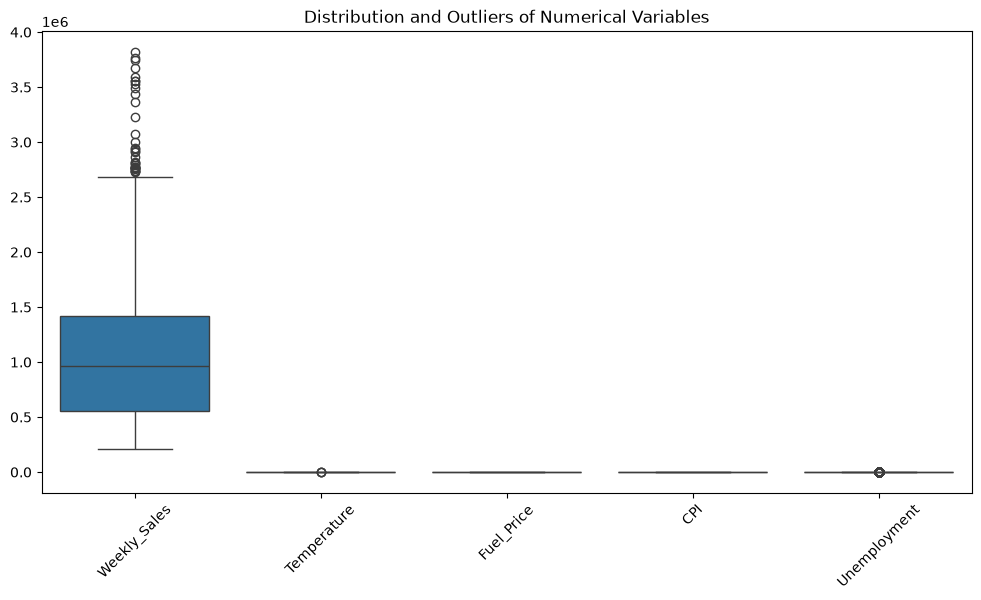

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[["Weekly_Sales", "Temperature", "Fuel_Price", "CPI", "Unemployment"]])
plt.xticks(rotation=45)
plt.title("Distribution and Outliers of Numerical Variables")
plt.show()

In [8]:
Q1 = df["Weekly_Sales"].quantile(0.25)
Q3 = df["Weekly_Sales"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Weekly_Sales"] < lower_bound) | (df["Weekly_Sales"] > upper_bound)]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Lower bound: -746862.7275
Upper bound: 2720371.4924999997
Number of outliers: 34
Percentage: 0.5283605283605284


Outliers are retained because extreme weekly sales can represent legitimate differences in store scale and holiday demand rather than data errors.

## 3. Exploratory Data Analysis


In [9]:
print("Average weekly sales:", df["Weekly_Sales"].mean())
print("Median weekly sales:", df["Weekly_Sales"].median())
print("Minimum weekly sales:", df["Weekly_Sales"].min())
print("Maximum weekly sales:", df["Weekly_Sales"].max())

Average weekly sales: 1046964.8775617715
Median weekly sales: 960746.04
Minimum weekly sales: 209986.25
Maximum weekly sales: 3818686.45


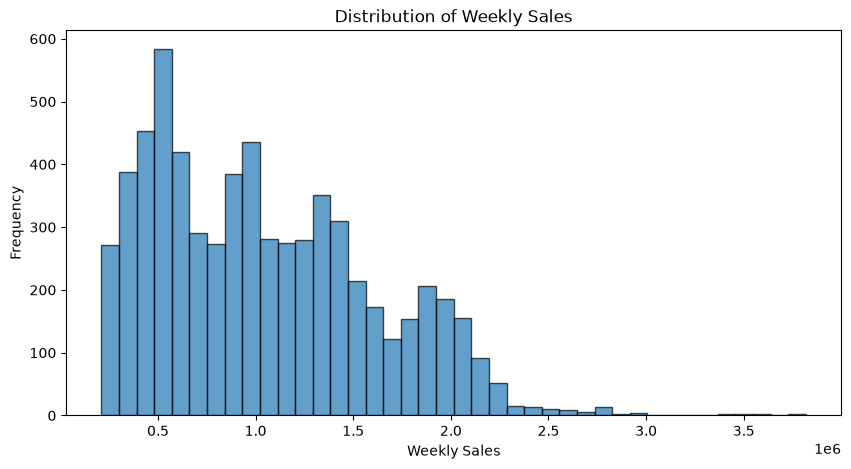

In [10]:
plt.figure(figsize=(10, 5))
plt.hist(df["Weekly_Sales"], bins=40, edgecolor="black", alpha=0.7)
plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")
plt.show()

### Unemployment and Weekly Sales

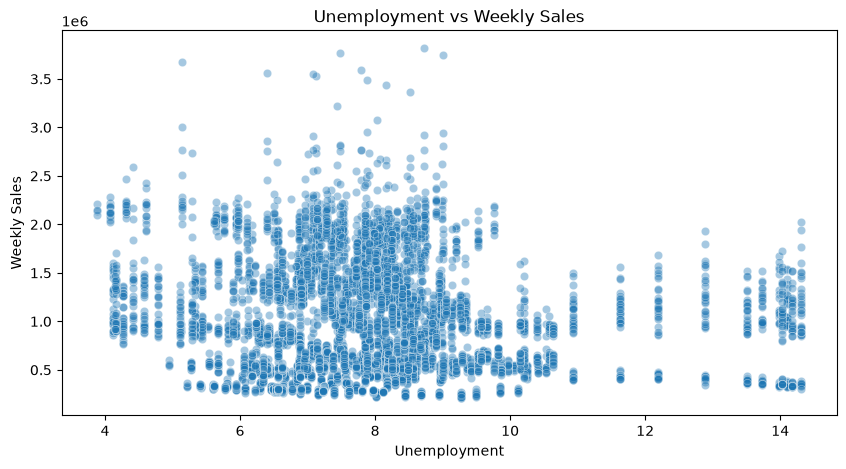

Overall correlation: -0.10617608965795418


In [11]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Unemployment", y="Weekly_Sales", alpha=0.4)
plt.title("Unemployment vs Weekly Sales")
plt.xlabel("Unemployment")
plt.ylabel("Weekly Sales")
plt.show()

print("Overall correlation:", df["Unemployment"].corr(df["Weekly_Sales"]))

In [12]:
store_unemployment_corr = (
    df.groupby("Store")
      .apply(lambda x: x["Unemployment"].corr(x["Weekly_Sales"]))
      .reset_index(name="Correlation")
      .sort_values("Correlation")
)

store_unemployment_corr.head(10)

,Store,Correlation
37,38,-0.785290
43,44,-0.780076
38,39,-0.384681
41,42,-0.356355
40,41,-0.350630
3,4,-0.337015
16,17,-0.263600
2,3,-0.230413
36,37,-0.221287
4,5,-0.207043


### Seasonality and Holiday Effect

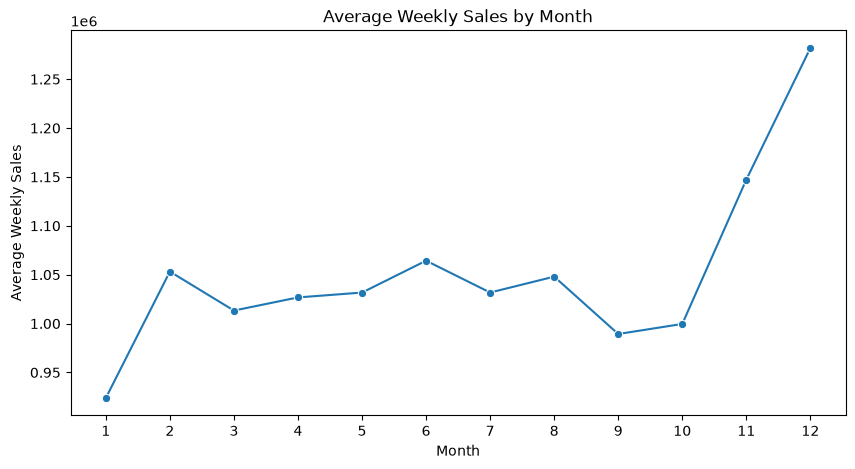

Highest-sales month: 12
Lowest-sales month: 1


In [13]:
monthly_sales = df.groupby("Month")["Weekly_Sales"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")
plt.title("Average Weekly Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales")
plt.xticks(range(1, 13))
plt.show()

print("Highest-sales month:", monthly_sales.idxmax())
print("Lowest-sales month:", monthly_sales.idxmin())

Holiday_Flag
0    1.041256e+06
1    1.122888e+06
Name: Weekly_Sales, dtype: float64


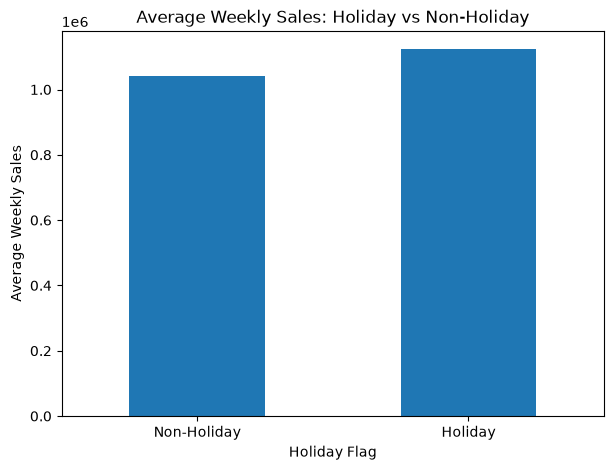

In [14]:
holiday_sales = df.groupby("Holiday_Flag")["Weekly_Sales"].mean()
print(holiday_sales)

holiday_sales.plot(kind="bar", figsize=(7, 5))
plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Holiday Flag")
plt.ylabel("Average Weekly Sales")
plt.xticks([0, 1], ["Non-Holiday", "Holiday"], rotation=0)
plt.show()

Holiday weeks show higher average sales in this dataset. This is consistent with increased retail demand around major shopping periods, although the analysis establishes association rather than causation.

### Temperature and Weekly Sales

Correlation: -0.06381001317946955


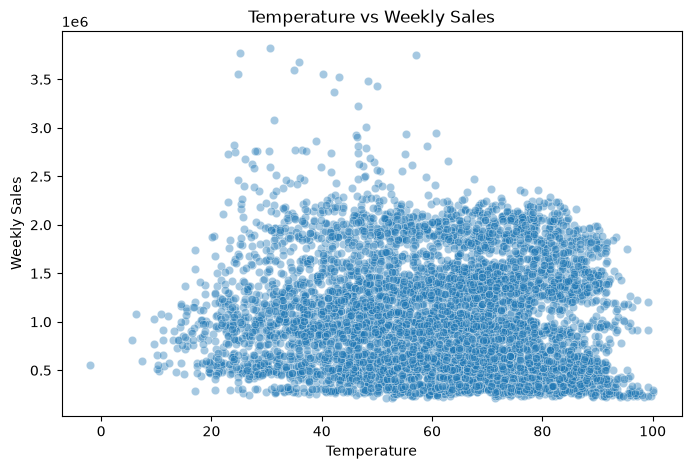

In [15]:
temp_corr = df["Temperature"].corr(df["Weekly_Sales"])
print("Correlation:", temp_corr)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Temperature", y="Weekly_Sales", alpha=0.4)
plt.title("Temperature vs Weekly Sales")
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.show()

### CPI and Weekly Sales

Overall correlation: -0.0726341620401763


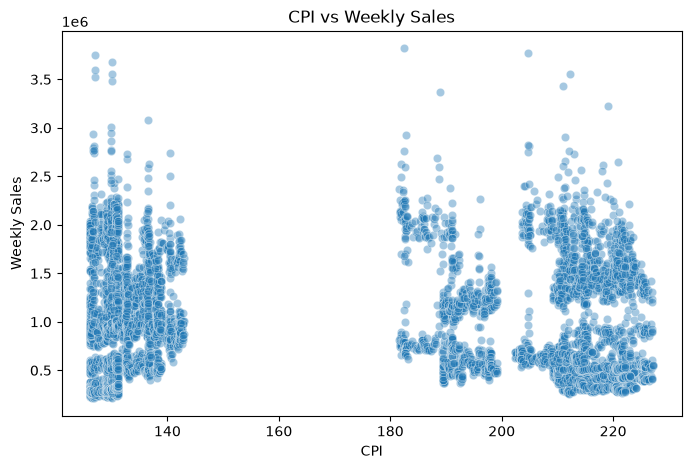

In [16]:
cpi_corr = df["CPI"].corr(df["Weekly_Sales"])
print("Overall correlation:", cpi_corr)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="CPI", y="Weekly_Sales", alpha=0.4)
plt.title("CPI vs Weekly Sales")
plt.xlabel("CPI")
plt.ylabel("Weekly Sales")
plt.show()

In [17]:
store_cpi_corr = (
    df.groupby("Store")
      .apply(lambda x: x["CPI"].corr(x["Weekly_Sales"]))
      .reset_index(name="Correlation")
      .sort_values("Correlation")
)

store_cpi_corr.head(10)

,Store,Correlation
35,36,-0.915095
34,35,-0.424107
13,14,-0.419755
29,30,-0.298188
42,43,-0.285686
26,27,-0.213082
17,18,-0.193541
14,15,-0.174467
20,21,-0.163649
18,19,-0.155341


## 4. Historical Store Performance

In [18]:
store_sales = (
    df.groupby("Store")["Weekly_Sales"]
      .mean()
      .sort_values(ascending=False)
)

print("Top 5 stores by historical average weekly sales:")
print(store_sales.head(5))


Top 5 stores by historical average weekly sales:
Store
20    2.107677e+06
4     2.094713e+06
14    2.020978e+06
13    2.003620e+06
2     1.925751e+06
Name: Weekly_Sales, dtype: float64


In [19]:
best_store = store_sales.idxmax()
worst_store = store_sales.idxmin()
best_sales = store_sales.max()
worst_sales = store_sales.min()

print("Best store:", best_store)
print("Best average weekly sales:", best_sales)
print("Worst store:", worst_store)
print("Worst average weekly sales:", worst_sales)
print("Difference between highest and lowest:", best_sales - worst_sales)


Best store: 20
Best average weekly sales: 2107676.8703496503
Worst store: 33
Worst average weekly sales: 259861.69202797202
Difference between highest and lowest: 1847815.1783216782


In [20]:
best_store_sales = df[df["Store"] == best_store]["Weekly_Sales"]
worst_store_sales = df[df["Store"] == worst_store]["Weekly_Sales"]

t_stat, p_value = ttest_ind(
    best_store_sales,
    worst_store_sales,
    equal_var=False
)

print("Welch t-statistic:", t_stat)
print("P-value:", p_value)

Welch t-statistic: 79.78456936141032
P-value: 3.52031912550115e-121


## 5. Store Segregation and Forecasting Setup

In [21]:
df = df.sort_values(["Store", "Date"])
sales_ts = df[["Store", "Date", "Weekly_Sales"]].copy()

store_data = {}
for store in sales_ts["Store"].unique():
    store_data[int(store)] = (
        sales_ts[sales_ts["Store"] == store]
        .sort_values("Date")
        .reset_index(drop=True)
    )

print("Number of stores:", len(store_data))
print("Observations per store:", store_data[1].shape[0])

Number of stores: 45
Observations per store: 143


In [22]:
train_data = []
test_data = []

for store in sales_ts["Store"].unique():
    store_ts = sales_ts[sales_ts["Store"] == store].sort_values("Date")
    train_data.append(store_ts.iloc[:-12])
    test_data.append(store_ts.iloc[-12:])

train_df = pd.concat(train_data)
test_df = pd.concat(test_data)

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 5895
Testing rows: 540


## 6. 12-Week Forecast for All Stores — Seasonal Naive Baseline

In [23]:
def seasonal_naive_forecast(train, horizon=12, season_length=52):
    return train.iloc[-season_length:-season_length + horizon].values

In [24]:
forecast_results = []

for store in sales_ts["Store"].unique():
    train = train_df[train_df["Store"] == store]["Weekly_Sales"].reset_index(drop=True)
    actual = test_df[test_df["Store"] == store]["Weekly_Sales"].values
    forecast = seasonal_naive_forecast(train, horizon=12)

    mae = np.mean(np.abs(actual - forecast))
    rmse = np.sqrt(np.mean((actual - forecast) ** 2))

    forecast_results.append({"Store": store, "MAE": mae, "RMSE": rmse})

forecast_results = pd.DataFrame(forecast_results)
forecast_results

,Store,MAE,RMSE
0,1,55165.045000,66848.813430
1,2,104826.942500,115390.796115
2,3,30587.902500,32863.674941
3,4,62698.647500,74520.702834
4,5,20385.035000,22640.882480
5,6,64088.276667,72945.111443
6,7,17119.683333,21663.547396
7,8,44910.150833,54251.562635
8,9,23306.650000,27216.357976
9,10,42955.555000,56741.838810


In [25]:
future_forecasts = []

for store in sales_ts["Store"].unique():
    store_ts = sales_ts[sales_ts["Store"] == store].sort_values("Date")
    sales = store_ts["Weekly_Sales"].reset_index(drop=True)
    forecast = seasonal_naive_forecast(sales, horizon=12)

    last_date = store_ts["Date"].max()
    future_dates = pd.date_range(
        start=last_date + pd.Timedelta(weeks=1),
        periods=12,
        freq="W-FRI"
    )

    for date, value in zip(future_dates, forecast):
        future_forecasts.append({
            "Store": store,
            "Date": date,
            "Forecasted_Sales": value
        })

future_forecasts = pd.DataFrame(future_forecasts)
future_forecasts.to_csv("../outputs/forecasts/12_week_forecasts.csv", index=False)
future_forecasts.head(12)

,Store,Date,Forecasted_Sales
0,1,2012-11-02,1697229.58
1,1,2012-11-09,1594938.89
2,1,2012-11-16,1539483.70
3,1,2012-11-23,2033320.66
4,1,2012-11-30,1584083.95
5,1,2012-12-07,1799682.38
6,1,2012-12-14,1881176.67
7,1,2012-12-21,2270188.99
8,1,2012-12-28,1497462.72
9,1,2013-01-04,1550369.92


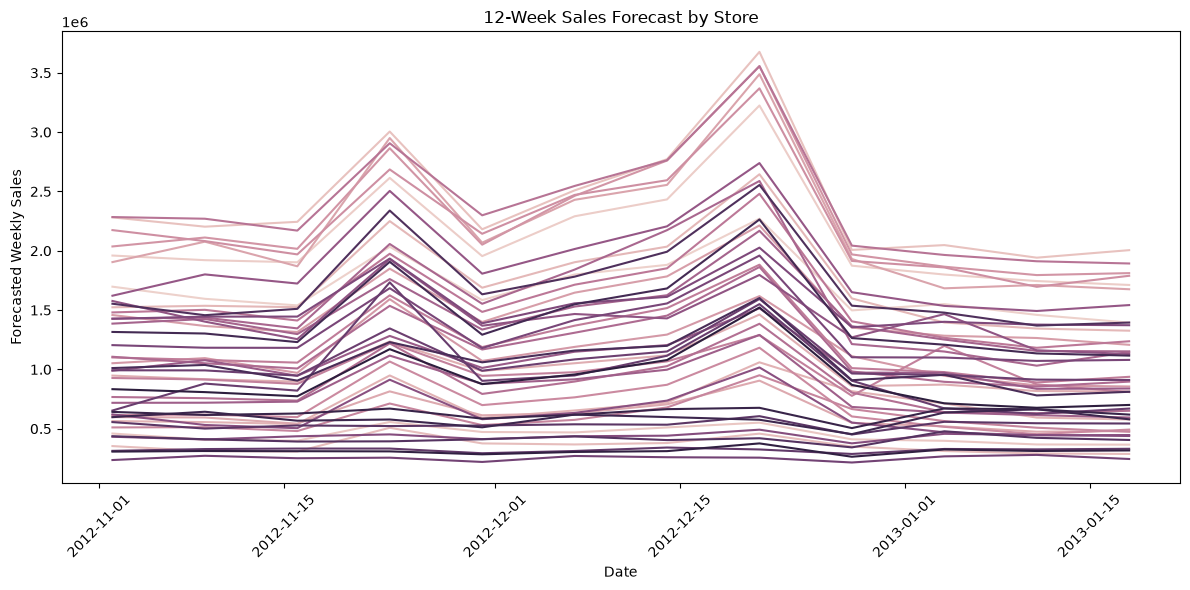

In [26]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=future_forecasts, x="Date", y="Forecasted_Sales", hue="Store", legend=False)
plt.title("12-Week Sales Forecast by Store")
plt.xlabel("Date")
plt.ylabel("Forecasted Weekly Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../outputs/figures/12_week_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. SARIMA Forecasting — Five Stores

To complement the all-store 12-week forecast, SARIMA is fitted separately to five historically top-performing stores. The final 12 weeks are held out for MAE/RMSE evaluation, then each model is refit on the full history to forecast the following 12 weeks.


In [27]:
selected_stores = store_sales.head(5).index.tolist()
print("Selected stores:", selected_stores)

store_series = {}
for store in selected_stores:
    store_series[store] = (
        df[df["Store"] == store]
        .sort_values("Date")
        .set_index("Date")["Weekly_Sales"]
    )

Selected stores: [20, 4, 14, 13, 2]


In [28]:
sarima_results = []
sarima_forecasts = {}

for store, series in store_series.items():
    train = series.iloc[:-12]
    test = series.iloc[-12:]

    model = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 52),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fitted_model = model.fit(disp=False)
    test_forecast = fitted_model.forecast(steps=12)

    mae = np.mean(np.abs(test.values - test_forecast.values))
    rmse = np.sqrt(np.mean((test.values - test_forecast.values) ** 2))
    sarima_results.append({"Store": store, "MAE": mae, "RMSE": rmse})

    full_model = SARIMAX(
        series,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 52),
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    full_fitted_model = full_model.fit(disp=False)
    sarima_forecasts[store] = full_fitted_model.forecast(steps=12)

sarima_results = pd.DataFrame(sarima_results)
sarima_results

d:\Programming\Project Walmart\walmart-sales-analysis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
d:\Programming\Project Walmart\walmart-sales-analysis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
d:\Programming\Project Walmart\walmart-sales-analysis\.venv\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
d:\Programming\Project Walmart\walmart-sales-analysis\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be us

,Store,MAE,RMSE
0,20,58091.643677,77834.417050
1,4,72764.113323,90941.221290
2,14,95978.976076,115164.598290
3,13,56110.847552,80787.713595
4,2,46161.842777,55528.266179


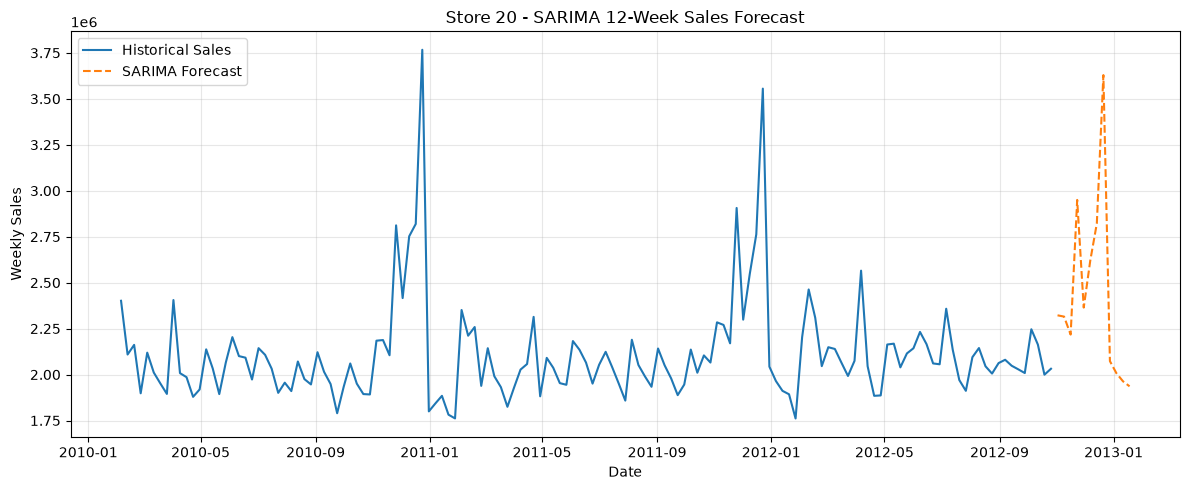

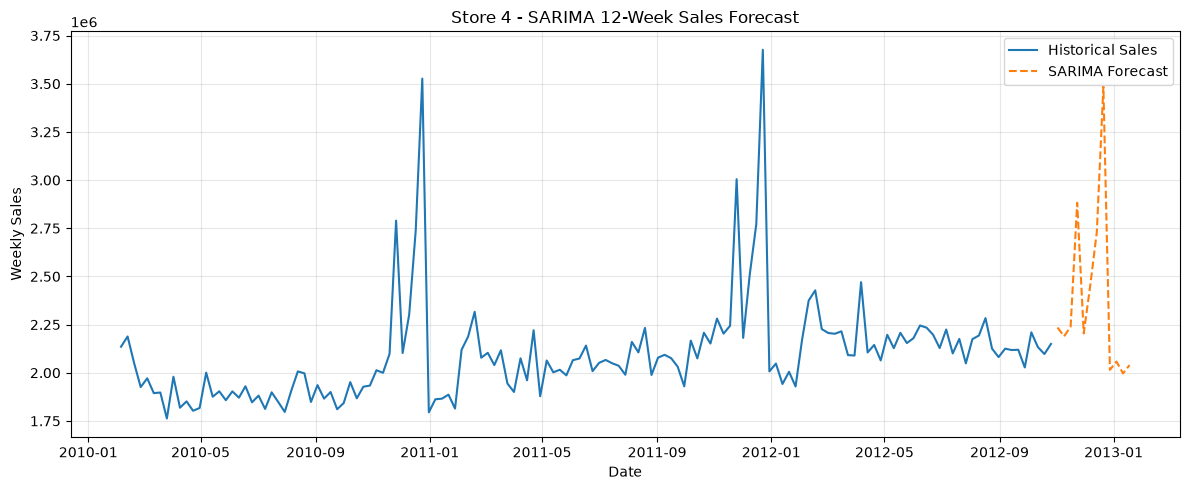

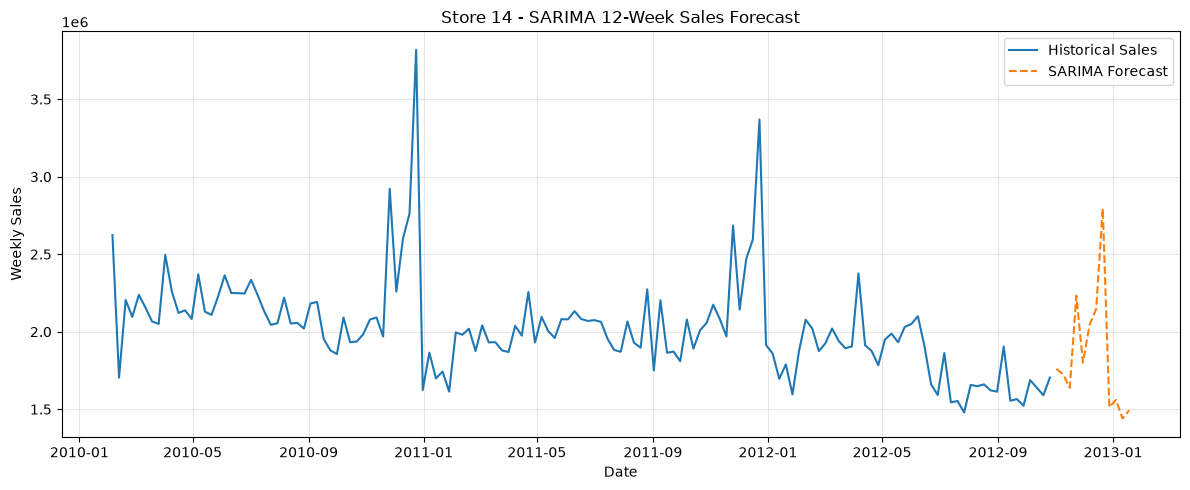

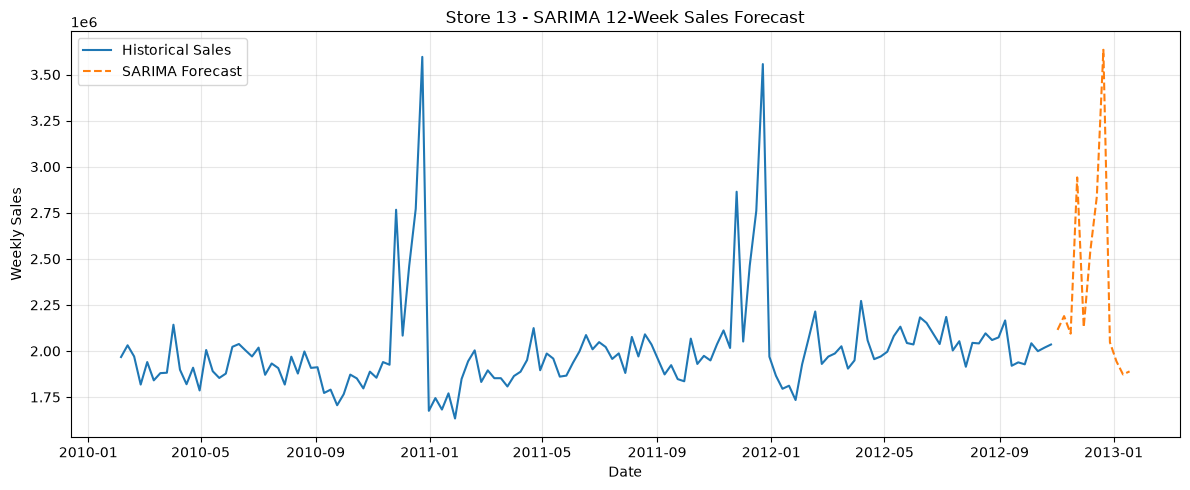

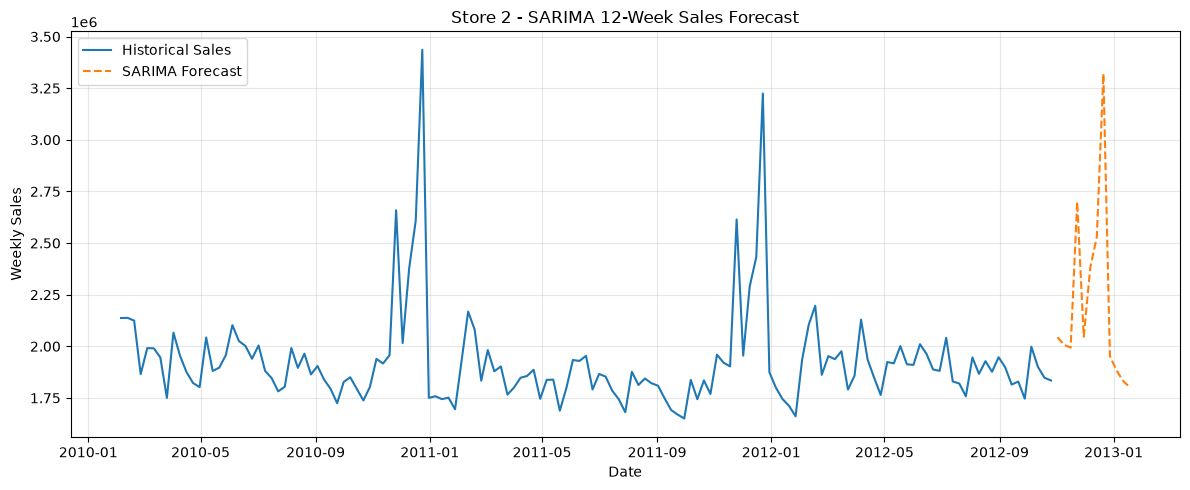

In [29]:
for store in selected_stores:
    series = store_series[store]
    future_forecast = sarima_forecasts[store]

    plt.figure(figsize=(12, 5))
    plt.plot(series.index, series.values, label="Historical Sales")
    plt.plot(future_forecast.index, future_forecast.values, label="SARIMA Forecast", linestyle="--")
    plt.title(f"Store {store} - SARIMA 12-Week Sales Forecast")
    plt.xlabel("Date")
    plt.ylabel("Weekly Sales")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [30]:
sarima_forecast_df = pd.concat(
    [
        pd.DataFrame({
            "Store": store,
            "Date": forecast.index,
            "Forecasted_Sales": forecast.values
        })
        for store, forecast in sarima_forecasts.items()
    ],
    ignore_index=True
)

sarima_forecast_df.to_csv("../outputs/forecasts/sarima_5_store_forecasts.csv", index=False)
sarima_forecast_df.head(15)

,Store,Date,Forecasted_Sales
0,20,2012-11-02,2.322377e+06
1,20,2012-11-09,2.315227e+06
2,20,2012-11-16,2.217460e+06
3,20,2012-11-23,2.949935e+06
4,20,2012-11-30,2.364469e+06
5,20,2012-12-07,2.620427e+06
6,20,2012-12-14,2.821845e+06
7,20,2012-12-21,3.629009e+06
8,20,2012-12-28,2.073027e+06
9,20,2013-01-04,2.006806e+06


## 8. Project Summary

## 8. Final Findings

This section summarizes the findings from the required business questions and the forecasting analysis.


# Conclusion

- **Unemployment:** Weekly sales have a weak negative overall relationship with unemployment. The store-level correlation analysis identifies the stores with the strongest negative relationships.
- **Seasonality:** Weekly sales vary by month, with the highest and lowest months identified from the monthly analysis. Holiday-week sales are also compared to non-holiday weeks to provide a possible explanation for seasonal variation.
- **Temperature:** The correlation and scatter plot quantify the relationship between temperature and weekly sales.
- **CPI:** Overall and store-level CPI correlations show how the relationship between CPI and weekly sales varies across stores.
- **Store performance:** Historical average weekly sales identify the top-performing stores and the worst-performing store. Welch's t-test evaluates whether the difference between the highest- and lowest-performing stores is statistically significant.
- **Forecasting:** A 52-week seasonal-naive forecasting model produces 12-week forecasts for every store. SARIMA is additionally evaluated on five stores to provide a formal seasonal time-series model comparison.
